In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


In [ ]:
df.to_csv("housing.csv", index=False)
print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


Inspecting Data

In [ ]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (20640, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Statistical Summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nOcean Proximity Categories:")
print(df["ocean_proximity"].value_counts())

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate Rows: 0

Ocean Proximity Categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


Exploratory Data Analysis (EDA)

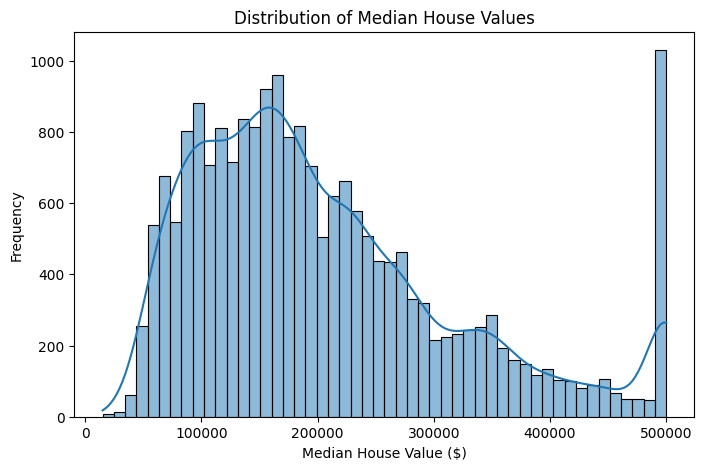

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["median_house_value"], bins=50, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Frequency")

plt.show()

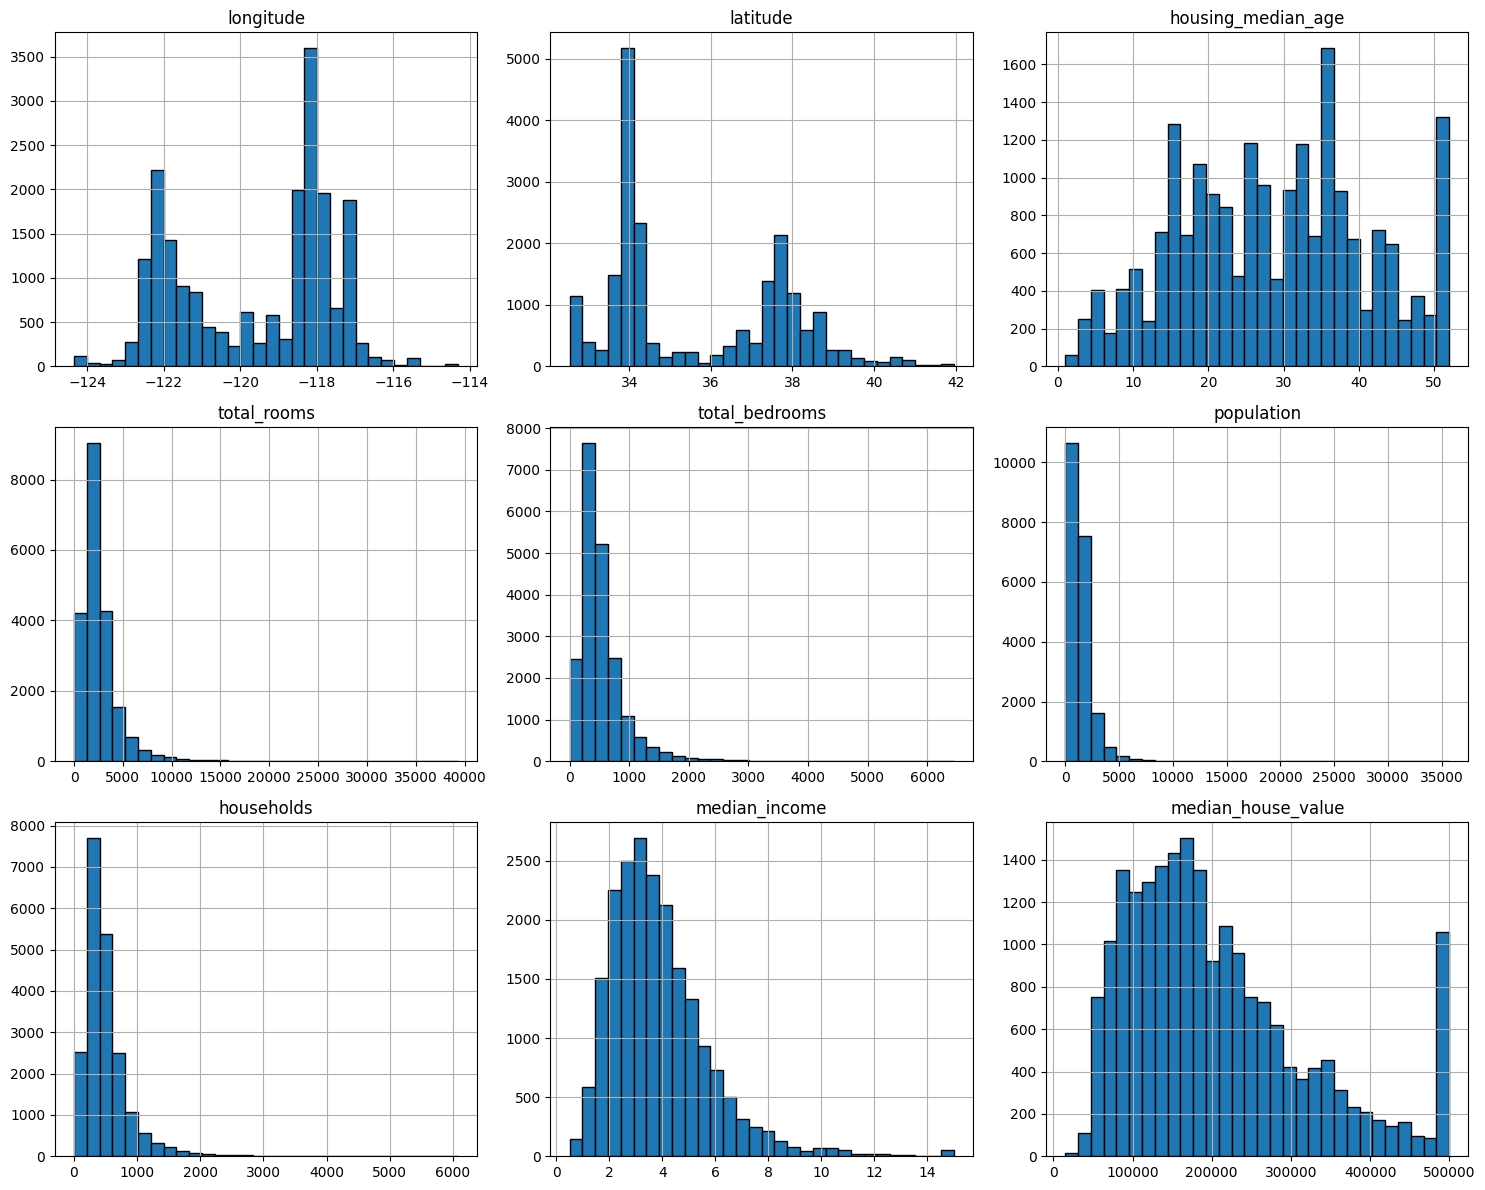

In [ ]:
df.hist(figsize=(15, 12), bins=30, edgecolor="black")

plt.tight_layout()
plt.show()

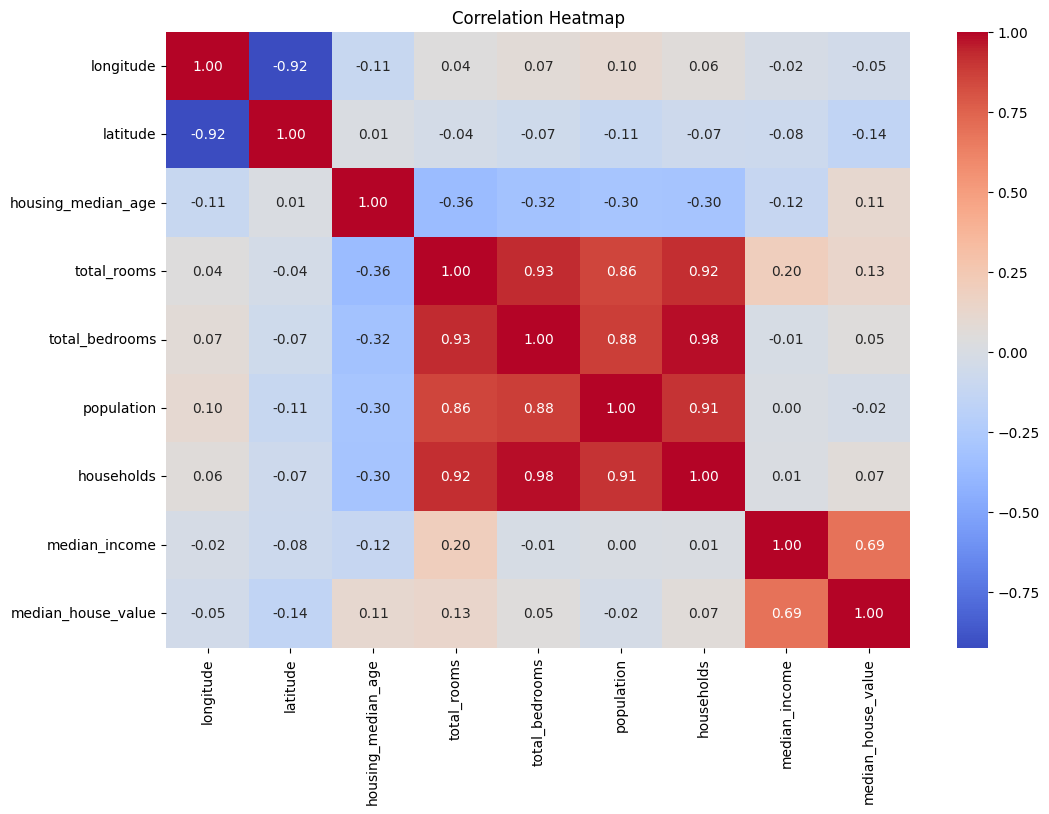

In [ ]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

Data Preprocessing

In [ ]:
# Create new features
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

df["population_per_household"] = (
    df["population"] / df["households"]
)

# Create an interaction feature
df["income_age_interaction"] = (
    df["median_income"] * df["housing_median_age"]
)

print("New features created successfully!")

display(df[[
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
    "income_age_interaction"
]].head())

New features created successfully!


,rooms_per_household,bedrooms_per_room,population_per_household,income_age_interaction
0,6.984127,0.146591,2.555556,341.3332
1,6.238137,0.155797,2.109842,174.3294
2,8.288136,0.129516,2.802260,377.3848
3,5.817352,0.184458,2.547945,293.4412
4,6.281853,0.172096,2.181467,200.0024


In [ ]:
# Separate features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Input features shape: (20640, 13)
Target shape: (20640,)

Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_age_interaction']

Categorical Features:
['ocean_proximity']


In [ ]:
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 13)
Testing data: (4128, 13)


Training Model

In [ ]:
# Create OLS pipeline
ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model
ols_model.fit(X_train, y_train)

# Make predictions
ols_predictions = ols_model.predict(X_test)

print("OLS Linear Regression trained successfully!")

OLS Linear Regression trained successfully!


In [ ]:
# Calculate evaluation metrics
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ols_mae = mean_absolute_error(y_test, ols_predictions)
ols_r2 = r2_score(y_test, ols_predictions)

print("OLS Model Performance")
print("---------------------")
print("RMSE:", round(ols_rmse, 2))
print("MAE:", round(ols_mae, 2))
print("R2 Score:", round(ols_r2, 4))

OLS Model Performance
---------------------
RMSE: 69048.19
MAE: 49376.49
R2 Score: 0.6362


In [ ]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

# Hyperparameter tuning
ridge_params = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_search = GridSearchCV(
    ridge_model,
    ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

# Best Ridge model
best_ridge = ridge_search.best_estimator_
ridge_predictions = best_ridge.predict(X_test)

print("Best Ridge Alpha:", ridge_search.best_params_)
print("Ridge model trained successfully!")

Best Ridge Alpha: {'model__alpha': 1}
Ridge model trained successfully!


In [ ]:
ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)

ridge_mae = mean_absolute_error(
    y_test, ridge_predictions
)

ridge_r2 = r2_score(
    y_test, ridge_predictions
)

print("Ridge Model Performance")
print("-----------------------")
print("RMSE:", round(ridge_rmse, 2))
print("MAE:", round(ridge_mae, 2))
print("R2 Score:", round(ridge_r2, 4))

Ridge Model Performance
-----------------------
RMSE: 69056.22
MAE: 49382.63
R2 Score: 0.6361


In [ ]:
lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=10000))
])

# Hyperparameter tuning
lasso_params = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

lasso_search = GridSearchCV(
    lasso_model,
    lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

# Best Lasso model
best_lasso = lasso_search.best_estimator_
lasso_predictions = best_lasso.predict(X_test)

print("Best Lasso Alpha:", lasso_search.best_params_)
print("Lasso model trained successfully!")

Best Lasso Alpha: {'model__alpha': 1}
Lasso model trained successfully!


In [ ]:
lasso_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_predictions)
)

lasso_mae = mean_absolute_error(
    y_test, lasso_predictions
)

lasso_r2 = r2_score(
    y_test, lasso_predictions
)

print("Lasso Model Performance")
print("-----------------------")
print("RMSE:", round(lasso_rmse, 2))
print("MAE:", round(lasso_mae, 2))
print("R2 Score:", round(lasso_r2, 4))

Lasso Model Performance
-----------------------
RMSE: 69049.25
MAE: 49377.34
R2 Score: 0.6362


Comparison

In [ ]:
results = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "RMSE": [ols_rmse, ridge_rmse, lasso_rmse],
    "MAE": [ols_mae, ridge_mae, lasso_mae],
    "R2 Score": [ols_r2, ridge_r2, lasso_r2]
})

display(results.round(4))

,Model,RMSE,MAE,R2 Score
0,OLS,69048.1923,49376.4886,0.6362
1,Ridge,69056.2204,49382.6281,0.6361
2,Lasso,69049.2483,49377.3433,0.6362


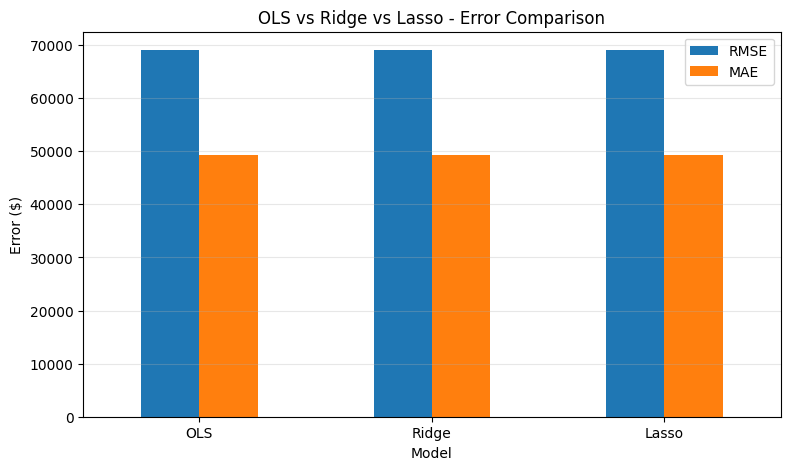

In [22]:
results.set_index("Model")[["RMSE", "MAE"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("OLS vs Ridge vs Lasso - Error Comparison")
plt.ylabel("Error ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

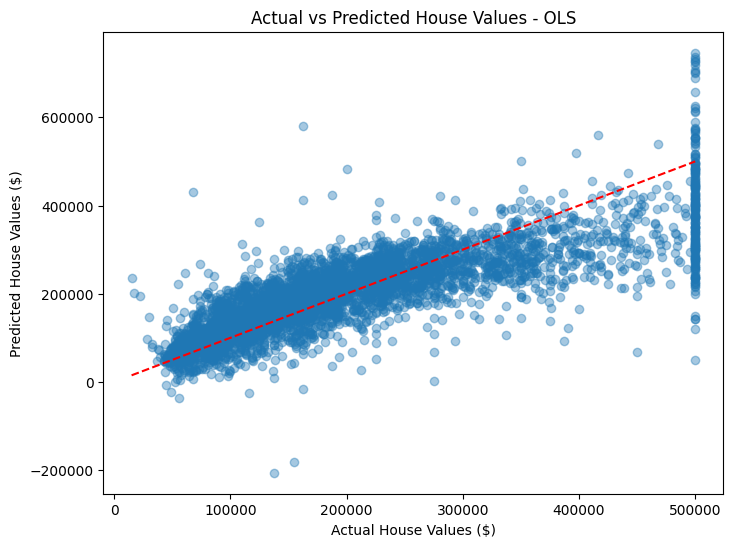

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    ols_predictions,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Values ($)")
plt.ylabel("Predicted House Values ($)")
plt.title("Actual vs Predicted House Values - OLS")

plt.show()

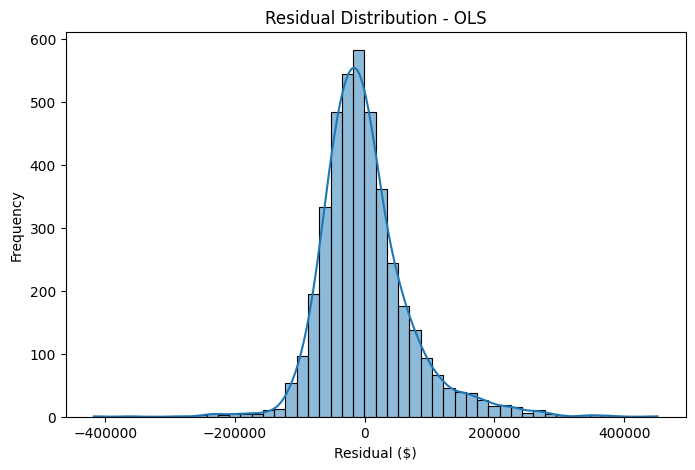

In [24]:
# Calculate residuals
ols_residuals = y_test - ols_predictions

# Plot residual distribution
plt.figure(figsize=(8, 5))

sns.histplot(ols_residuals, bins=50, kde=True)

plt.title("Residual Distribution - OLS")
plt.xlabel("Residual ($)")
plt.ylabel("Frequency")

plt.show()

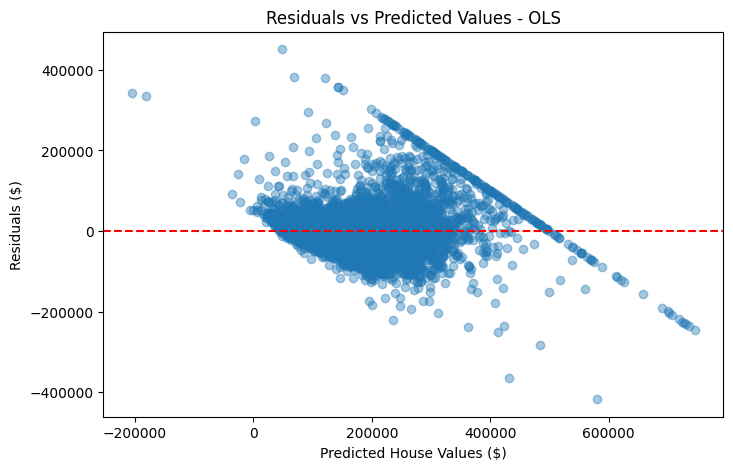

In [25]:
# Residuals vs predicted values
plt.figure(figsize=(8, 5))

plt.scatter(
    ols_predictions,
    ols_residuals,
    alpha=0.4
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Values ($)")
plt.ylabel("Residuals ($)")
plt.title("Residuals vs Predicted Values - OLS")

plt.show()

## Conclusion

In this project, we developed a California Housing Price Prediction system using three regression algorithms: Ordinary Least Squares (OLS), Ridge Regression (L2), and Lasso Regression (L1).

The dataset contained 20,640 records. We handled missing values using median imputation, encoded categorical variables, standardized numerical features, and created four additional features through feature engineering.

GridSearchCV was used to tune the regularization parameter (alpha) for Ridge and Lasso.

### Model Performance

| Model | RMSE | MAE | R² |
|---|---:|---:|---:|
| OLS | 69048.19 | 49376.49 | 0.6362 |
| Ridge | 69056.22 | 49382.63 | 0.6361 |
| Lasso | 69049.25 | 49377.34 | 0.6362 |

OLS achieved the best overall performance, with the lowest RMSE and MAE.

### Key Findings

- Median income showed the strongest correlation with median house value.
- Several numerical features exhibited multicollinearity.
- Ridge and Lasso regularization produced results very similar to OLS.
- Residual analysis revealed non-constant error variance and potential effects from the dataset's house-price ceiling.

### Final Outcome

The project demonstrated a complete regression workflow, including exploratory data analysis, feature engineering, preprocessing, hyperparameter tuning, model evaluation, and residual analysis.